# Scenario 1 - Metabolic Day

This scenario simulates a sequence of metabolic states:

1. Baseline glucose metabolism
2. Mixed meal
3. High energy demand
4. Predominantly fat metabolism
5. Recovery

The objective is to observe:

- AcCoA dynamics
- Citrate dynamics
- Malonyl-CoA dynamics
- TAG accumulation
- Regulatory responses

In [2]:
# ============================================================
# Scenario Notebook 01
#
# Metabolic Day
#
# Explore dynamic responses to changing substrate
# availability and energy demand.
# ============================================================

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from model_interface import *
import kinetics

In [4]:
def print_states(state):

    print("\nFINAL STATES")
    print("-" * 40)

    for name, value in zip(
        kinetics.STATE_NAMES,
        state
    ):
        print(f"{name:15s} {value:10.4f}")


def print_derivatives(state, inputs):

    dxdt = derivatives(
        0,
        state,
        inputs
    )

    print("\nFINAL DERIVATIVES")
    print("-" * 40)

    for name, value in zip(
        kinetics.STATE_NAMES,
        dxdt
    ):
        print(f"{name:15s} {value:10.6f}")


def print_fluxes(state, inputs):

    fluxes = kinetics.compute_fluxes(
        state,
        inputs
    )

    print("\nFINAL FLUXES")
    print("-" * 40)

    for name, value in fluxes.items():
        print(f"{name:15s} {value:10.6f}")

In [6]:
# ------------------------------------------------------------
# Scenario 01 - Metabolic Day
#
# Phase 1 : Glucose baseline
# Phase 2 : Mixed meal
# Phase 3 : Increased workload
# Phase 4 : Fat-dominant metabolism
# Phase 5 : Recovery
# ------------------------------------------------------------

state = kinetics.DEFAULT_STATE.copy()

history = []

input_glu = []
input_fat = []
input_atp = []

for step in range(5000):

    if step < 1000:

        glu_in = 1.0
        fat_in = 0.0
        atp_draw = 1.0

    elif step < 2000:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 1.0

    elif step < 3000:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 2.0

    elif step < 4000:

        glu_in = 0.0
        fat_in = 1.0
        atp_draw = 1.0

    else:

        glu_in = 0.5
        fat_in = 0.5
        atp_draw = 0.5

    state, flux = step_ivp_once(
        state,
        glu_in=glu_in,
        fat_in=fat_in,
        atp_draw=atp_draw
    )

    history.append(state.copy())

    input_glu.append(glu_in)
    input_fat.append(fat_in)
    input_atp.append(atp_draw)

history = np.array(history)

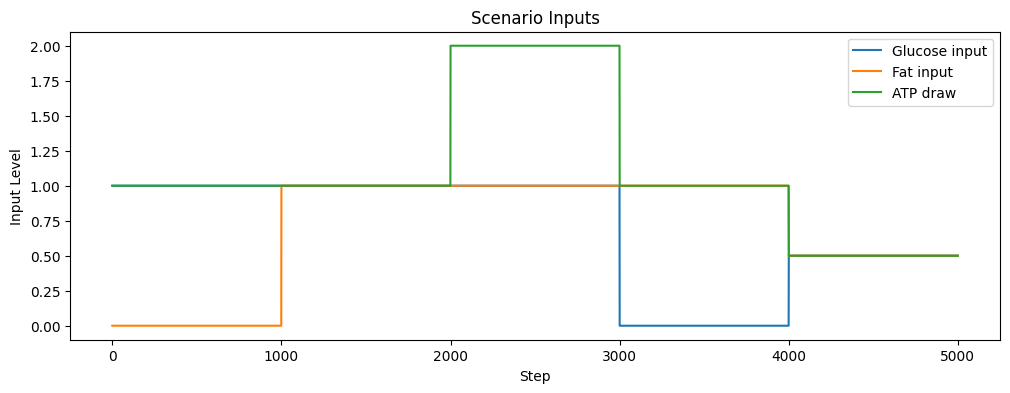

In [7]:
plt.figure(figsize=(12, 4))

plt.plot(input_glu, label="Glucose input")
plt.plot(input_fat, label="Fat input")
plt.plot(input_atp, label="ATP draw")

plt.title("Scenario Inputs")
plt.xlabel("Step")
plt.ylabel("Input Level")
plt.legend()
plt.show()

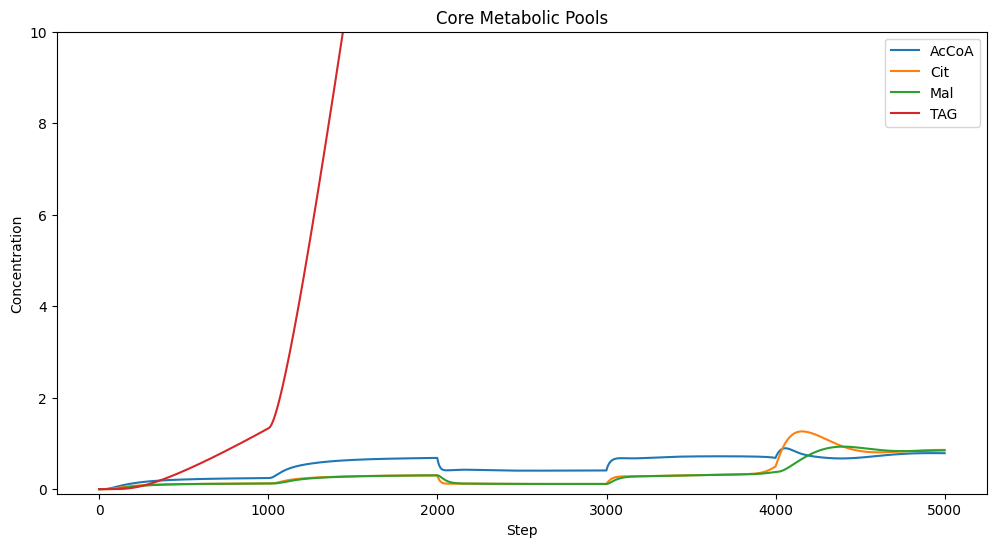

In [9]:
plt.figure(figsize=(12, 6))

for metabolite in [
    "AcCoA",
    "Cit",
    "Mal",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Core Metabolic Pools")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 10)
plt.legend()
plt.show()

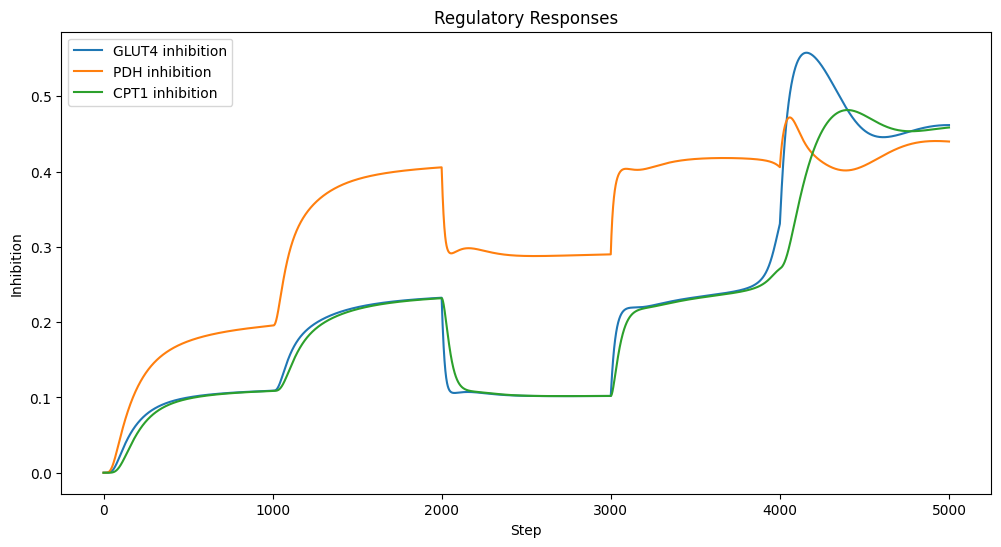

In [10]:
inh_glut4 = []
inh_pdh = []
inh_cpt1 = []

for state_row in history:

    inhib = kinetics.compute_inhibitions(
        state_row
    )

    inh_glut4.append(inhib["GLUT4"])
    inh_pdh.append(inhib["PDH"])
    inh_cpt1.append(inhib["CPT1"])

plt.figure(figsize=(12, 6))

plt.plot(inh_glut4, label="GLUT4 inhibition")
plt.plot(inh_pdh, label="PDH inhibition")
plt.plot(inh_cpt1, label="CPT1 inhibition")

plt.title("Regulatory Responses")
plt.xlabel("Step")
plt.ylabel("Inhibition")
plt.legend()
plt.show()

In [11]:
inputs = {
    "glu_in": glu_in,
    "fat_in": fat_in,
    "atp_draw": atp_draw
}

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)


FINAL STATES
----------------------------------------
Glc_ext             5.3917
Glc                 0.8277
Glc6P               0.2925
Fru6P               0.7168
Fru16P2             0.2890
Pyruvate            0.4027
AcCoA               0.7857
Cit                 0.8582
LCFA_ext            1.1162
LCFA_CoA_cyto      10.5970
LCFA_CoA_mito       0.9930
Mal                 0.8472
TAG                91.0571

FINAL DERIVATIVES
----------------------------------------
Glc_ext           0.046050
Glc               0.001090
Glc6P             0.000211
Fru6P             0.001636
Fru16P2           0.000473
Pyruvate          0.000609
AcCoA            -0.000997
Cit              -0.000081
LCFA_ext         -0.027457
LCFA_CoA_cyto    -0.173329
LCFA_CoA_mito    -0.003577
Mal               0.001456
TAG               0.413810

FINAL FLUXES
----------------------------------------
GLUT4             0.453950
Glycolysis        0.224215
PDH               0.160755
Citrate_prod      0.440004
ACL_ACC           0.

## Interpretation

Observe:

- When fat is introduced, citrate and malonyl-CoA should increase.
- Increased citrate should activate GLUT4 inhibition.
- Increased malonyl-CoA should activate CPT1 inhibition.
- TAG should behave as a long-term storage pool.
- Increased ATP demand should reduce AcCoA and citrate accumulation.

Questions:

- Does the model return toward a steady state after each transition?
- Which regulatory mechanism responds most strongly?
- Under which conditions does TAG accumulate fastest?